<a href="https://colab.research.google.com/github/ang-nc/Fisica-computacional-02/blob/main/Taller%204/T4_NumerosAleatorios_Difusion_Python_revisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller 4: Medir la difusión con caminatas aleatorias

## ¿cómo se dispersa una partícula?

Imagine una pequeña gota de leche en agua quieta. Una partícula de la gota cambia muchas veces de dirección al interactuar con las moléculas que la rodean. Seguir su recorrido exacto sería difícil y, por sí solo, diría poco sobre el tiempo que tarda la gota en dispersarse. Una caminata aleatoria nos permite estudiar una pregunta más útil: **¿a qué ritmo se alejan, en promedio, muchas partículas de su posición inicial?**

<figure>
  <img src="https://github.com/carlospi2000/Notes_on_Computational_Physics/blob/main/04.Random_Numbers_generation_PYTHON/Difusion_2D_red_cuadrada.gif?raw=1" width="350"
       alt="Caminata aleatoria en una red bidimensional">
  <figcaption>
    Figura 1. Caminata aleatoria de una partícula en una red bidimensional.
  </figcaption>
</figure>

Puede imaginar también a una persona intentando desplazarse entre la multitud de un concierto: cada encuentro puede alterar su dirección. Es solo una analogía; en una multitud puede haber preferencias de movimiento que nuestro modelo simétrico no incluye. Para empezar, simplificaremos el espacio a una línea y haremos que cada partícula dé pasos independientes de longitud $a$ hacia la izquierda o la derecha.

El resultado que buscaremos no es la trayectoria de una partícula «típica», sino $\langle x_n^2\rangle$ para muchas partículas. Su crecimiento permite estimar el coeficiente de difusión $D$. Según el modelo, si una dispersión característica requiere recorrer **el doble de distancia**, necesita aproximadamente **cuatro veces más tiempo**. ¿Lo respaldarán los resultados de la simulación?

## Propósito

Escriba en Python un flujo reproducible que simule $K$ caminantes con $N$ pasos, estime $\langle x_n\rangle$ y $\langle x_n^2\rangle$ **para cada** $n=0,\ldots,N$, ajuste una recta y calcule el coeficiente de difusión $D$. Use inicialmente $a=1$, $\Delta t=1$, $N=200$ y $K=2000$. Luego explore otro valor de $K$ y compare la dispersión de los resultados. Fije una semilla para el resultado entregado.

**Reglas de implementación:** construya la simulación y las sumas con ciclos y acumuladores propios; no use `np.random`, `np.cumsum` o `np.polyfit` para reemplazar el trabajo asignado. Puede usar NumPy para arreglos y lectura, y Matplotlib para la figura. Comente los pasos importantes y explique qué representa cada acumulador.

### Antes del taller — Funciones, argumentos y `return`

Una función reúne instrucciones que podemos ejecutar varias veces. `def` define su nombre y sus parámetros; los argumentos son los valores que le entregamos al llamarla. `return` devuelve el resultado al código que hizo la llamada. Definir una función no ejecuta su cuerpo.

El ejemplo siguiente calcula un desplazamiento a partir de una velocidad y un tiempo. Después otra función usa ese resultado. En el taller ocurrirá algo similar: `simular_caminatas` llama a `caminar`, y esta llama a `generar_paso`.

In [ ]:

# Definimos una función que calcula el desplazamiento de un objeto
# a partir de su velocidad constante y el tiempo transcurrido.
def desplazamiento(velocidad, tiempo):

    # Documentamos el propósito de la función y aclaramos
    # que devuelve el resultado sin imprimirlo en pantalla.
    """Devuelve v*t; no imprime el resultado dentro de la función."""

    # Calculamos el desplazamiento multiplicando la velocidad
    # por el tiempo, según la expresión física Δx = v*t.
    return velocidad * tiempo


# Definimos una función para calcular la posición final del objeto.
# Recibe la posición inicial, la velocidad y el tiempo transcurrido.
def posicion_final(x_inicial, velocidad, tiempo):

    # Documentamos que reutilizamos la función desplazamiento
    # para evitar repetir el cálculo y obtener el cambio de posición.
    """Usa otra función y devuelve la nueva posición."""

    # Llamamos a desplazamiento con la velocidad y el tiempo.
    # El resultado representa cuánto cambió la posición del objeto.
    cambio = desplazamiento(velocidad, tiempo)

    # Sumamos el desplazamiento a la posición inicial
    # para calcular la posición final: x_f = x_0 + Δx.
    return x_inicial + cambio


# Llamamos a la función con posición inicial de 2.0,
# velocidad constante de 3.0 y tiempo de 4.0.
resultado = posicion_final(2.0, 3.0, 4.0)

# Mostramos la posición final calculada por el programa.
print("Posición final:", resultado)  # Resultado esperado: 14.0



Posición final: 14.0


En `simular_caminatas`, el parámetro `generador=None` es opcional. Si se omite, la función crea `random.Random(semilla)`. Si se entrega un objeto generador, usa ese objeto. `None` significa que no se proporcionó uno. La clase `GeneradorLCG` se suministra completa: para este taller basta con saber que su método `.random()` entrega el siguiente número.

## Parte A — Funciones de la simulación

Complete las tres funciones de la siguiente celda:


1. `generar_paso(rng,a)`: consuma **un** número del generador recibido y devuelva $+a$ o $-a$.

In [ ]:
def generar_paso(rng, a):
    """Devuelve +a o -a según el número aleatorio generado."""

    # Obtiene un solo número aleatorio del generador recibido.
    # Usamos el generador recibido para poder cambiarlo en la Parte D.
    u = rng.random()

    # Si u es menor que 0.5, el paso es hacia la derecha.
    if u < 0.5:
        return a

    # Si u es mayor o igual que 0.5, el paso es hacia la izquierda.
    else:
        return -a


def caminar(N, a, rng):
    """Construye [x_0, x_1, ..., x_N] a partir del generador recibido."""
    # TODO: valide los parámetros; empiece con x=0 y posiciones=[0].
    # En cada iteración llame a generar_paso, actualice x y guarde x.
    raise NotImplementedError("Complete caminar")


def simular_caminatas(K, N, a, semilla, generador=None):
    """Promedia x_n y x_n² en K caminatas; incluye el índice n=0.

    Si generador es None se usa random.Random(semilla); en caso contrario se
    usa el objeto recibido, que solo necesita un método random() en [0, 1).
    """
    # TODO: valide los parámetros.
    # Si generador es None, construya rng=random.Random(semilla);
    # si no, use rng=generador.
    # Cree dos arreglos de N+1 ceros. Para cada caminante:
    #   trayectoria = caminar(N, a, rng)
    #   para cada n, agregue trayectoria[n] y trayectoria[n]**2.
    # Divida los acumuladores por K y devuelva ambos promedios.
    raise NotImplementedError("Complete simular_caminatas")

In [ ]:

# Define un generador de prueba que entrega valores predeterminados.
class RngControlado:
    def __init__(self, valores):
        # Convierte los valores en un iterador para entregarlos uno por uno.
        self.valores = iter(valores)

    def random(self):
        # Devuelve el siguiente valor de la secuencia de prueba.
        return next(self.valores)


# Comprueba un valor menor que 0.5: debe producir +2.
paso_derecha = generar_paso(RngControlado([0.2]), 2.0)

# Comprueba un valor igual a 0.5: debe producir -2.
paso_izquierda = generar_paso(RngControlado([0.5]), 2.0)

# Muestra los resultados para compararlos con los valores esperados.
print("Paso hacia la derecha:", paso_derecha)
print("Paso hacia la izquierda:", paso_izquierda)


Paso hacia la derecha: 2.0
Paso hacia la izquierda: -2.0


2. `caminar(N,a,rng)`: valide $N\geq0$ y $a>0$; devuelva **$N+1$ posiciones**, incluida $x_0=0$.

In [ ]:

def caminar(N, a, rng):
    """Devuelve las posiciones del caminante desde x_0 hasta x_N."""

    # Verifica que N sea un entero no negativo.
    # Si no se cumple, la función informa que el parámetro es inválido.
    if not isinstance(N, int) or isinstance(N, bool) or N < 0:
        raise ValueError("N debe ser un entero no negativo")

    # Verifica que la longitud de cada paso sea positiva.
    # Una longitud nula o negativa no cumple las condiciones del taller.
    if a <= 0:
        raise ValueError("a debe ser positiva")

    # El caminante comienza en el origen.
    # Guardamos esta posición porque la trayectoria debe incluir x_0.
    x = 0.0
    posiciones = [x]

    # Repite el proceso exactamente N veces, una por cada paso.
    for n in range(N):

        # Obtiene un paso de longitud +a o -a usando la función anterior.
        paso = generar_paso(rng, a)

        # Actualiza la posición sumando el nuevo paso.
        x = x + paso

        # Guarda la nueva posición para completar la trayectoria.
        posiciones.append(x)

    # Devuelve las N+1 posiciones, desde x_0 hasta x_N.
    return posiciones


In [ ]:

# Usa valores aleatorios controlados para comprobar la trayectoria.
# Los valores menores que 0.5 producen +a; los demás producen -a.
rng_prueba = RngControlado([0.1, 0.7, 0.2, 0.8])

# Simula cuatro pasos de longitud 2.
trayectoria = caminar(N=4, a=2.0, rng=rng_prueba)

# Muestra la trayectoria obtenida.
print("Trayectoria:", trayectoria)

# Comprueba el caso especial N=0: solo debe existir la posición inicial.
rng_vacio = RngControlado([])
print("Trayectoria para N=0:", caminar(N=0, a=2.0, rng=rng_vacio))


Trayectoria: [0.0, 2.0, 0.0, 2.0, 0.0]
Trayectoria para N=0: [0.0]


3. `simular_caminatas(K,N,a,semilla,generador=None)`: valide $K>0$, $N\geq0$ y $a>0$. Si `generador` es `None`, cree **un solo** `random.Random(semilla)` al inicio; si se entrega un generador, úselo en su lugar (lo necesitará en la Parte D). Pase ese mismo generador a cada caminata y acumule $x_n$ y $x_n^2$ para todos los $n$.

4. Divida cada suma por $K$ **después** del ciclo sobre caminantes. Devuelva `(media_x, media_x2)`.

Use `ValueError` para parámetros inválidos. No reinicie la semilla dentro del ciclo de caminantes: eso repetiría la misma trayectoria $K$ veces.


In [ ]:

# Importa el módulo que permite generar números aleatorios.
import random


In [ ]:

def simular_caminatas(K, N, a, semilla, generador=None):
    """Simula K caminatas y calcula los promedios de x_n y x_n^2."""

    # Verifica que K sea un entero positivo.
    # Se necesita al menos una caminata para calcular promedios.
    if not isinstance(K, int) or isinstance(K, bool) or K <= 0:
        raise ValueError("K debe ser un entero positivo")

    # Verifica que N sea un entero no negativo.
    # N representa la cantidad de pasos de cada caminata.
    if not isinstance(N, int) or isinstance(N, bool) or N < 0:
        raise ValueError("N debe ser un entero no negativo")

    # Verifica que la longitud de cada paso sea positiva.
    if a <= 0:
        raise ValueError("a debe ser positiva")

    # Si no se entrega un generador, crea uno usando la semilla.
    # Se crea una sola vez para que las caminatas compartan la secuencia.
    if generador is None:
        rng = random.Random(semilla)
    else:
        # Si se entrega un generador, utiliza ese mismo objeto.
        # Esto permite usar otros generadores en las siguientes partes.
        rng = generador

    # Crea acumuladores para sumar las posiciones y sus cuadrados.
    # Cada lista tiene una entrada para cada instante, desde 0 hasta N.
    suma_x = [0.0] * (N + 1)
    suma_x2 = [0.0] * (N + 1)

    # Simula las K caminatas utilizando el mismo generador.
    for k in range(K):

        # Obtiene todas las posiciones de una caminata.
        # La trayectoria contiene N+1 posiciones, incluida la inicial.
        posiciones = caminar(N, a, rng)

        # Recorre cada instante de la trayectoria para acumular resultados.
        for n in range(N + 1):

            # Suma la posición x_n de esta caminata.
            suma_x[n] += posiciones[n]

            # Suma el cuadrado de la posición x_n de esta caminata.
            suma_x2[n] += posiciones[n] ** 2

    # Divide las sumas entre K para obtener los promedios.
    # Se hace después de terminar todas las caminatas.
    media_x = [suma / K for suma in suma_x]
    media_x2 = [suma / K for suma in suma_x2]

    # Devuelve ambos promedios en el orden solicitado.
    return media_x, media_x2


<div style="background-color:#eef7ee; border-left:5px solid #4caf50; padding:10px 15px; margin:10px 0;"><b>Prueba manual:</b> para <code>N=0</code>, la trayectoria y ambos promedios deben contener solamente el cero inicial.</div>

In [ ]:

# Prueba el caso N=0: todas las caminatas permanecen en el origen.
media_x, media_x2 = simular_caminatas(
    K=3,
    N=0,
    a=2.0,
    semilla=42
)

# Muestra los promedios obtenidos.
print("Promedio de x_n:", media_x)
print("Promedio de x_n^2:", media_x2)


Promedio de x_n: [0.0]
Promedio de x_n^2: [0.0]


In [ ]:

# Simula 100 caminatas, cada una con 10 pasos de longitud 1.
# La misma semilla permite reproducir los resultados.
media_x, media_x2 = simular_caminatas(
    K=100,
    N=10,
    a=1.0,
    semilla=42
)

# Comprueba que ambos resultados tengan N+1 = 11 valores.
print("Cantidad de valores de media_x:", len(media_x))
print("Cantidad de valores de media_x2:", len(media_x2))

# Muestra los promedios en el último instante.
print("Promedio de x_N:", media_x[-1])
print("Promedio de x_N^2:", media_x2[-1])


Cantidad de valores de media_x: 11
Cantidad de valores de media_x2: 11
Promedio de x_N: -0.4
Promedio de x_N^2: 9.28


Construye la simulación dividiendo la lógica en componentes modulares (generar_paso, caminar y simular_caminatas). Garantiza el uso de una única semilla por simulación para evitar trayectorias idénticas y valida los parámetros de entrada.

## Parte B — Ajuste y coeficiente de difusión

Complete el ajuste con las sumas de la sección 4. La función debe devolver `(pendiente, intercepto)` y usar `ValueError` si las listas tienen distinta longitud, hay menos de dos puntos o el denominador es cero. No sustituya el ajuste por una llamada a `np.polyfit`. Compruebe primero el ejemplo exacto $y=3x+2$ y luego úselo con los valores simulados de $\langle x_n^2\rangle$.

In [ ]:

def ajuste_lineal(x, y):
    """Ajuste y = m*x + b con sumas explícitas; devuelve (m, b)."""

    # Verifica que ambas listas tengan la misma cantidad de datos.
    # Cada valor de x debe corresponder a un valor de y.
    if len(x) != len(y):
        raise ValueError("x e y deben tener la misma longitud")

    # Verifica que existan al menos dos puntos para realizar el ajuste.
    if len(x) < 2:
        raise ValueError("Se necesitan al menos dos puntos")

    # Calcula las sumas necesarias para el método de mínimos cuadrados.
    # sx: suma de los valores de x.
    # sy: suma de los valores de y.
    # sxx: suma de los cuadrados de x.
    # sxy: suma de los productos x*y.
    sx = sum(x)
    sy = sum(y)
    sxx = sum(valor ** 2 for valor in x)
    sxy = sum(x[i] * y[i] for i in range(len(x)))

    # Calcula el denominador de las expresiones de la pendiente.
    denominador = len(x) * sxx - sx ** 2

    # Evita dividir entre cero cuando los datos de x no permiten
    # determinar una pendiente única.
    if denominador == 0:
        raise ValueError("El denominador del ajuste es cero")

    # Calcula la pendiente m mediante las sumas anteriores.
    pendiente = (len(x) * sxy - sx * sy) / denominador

    # Calcula el intercepto b de la recta y = m*x + b.
    intercepto = (sy - pendiente * sx) / len(x)

    # Devuelve primero la pendiente y luego el intercepto.
    return pendiente, intercepto


In [ ]:

# Define puntos que cumplen exactamente la recta y = 3*x + 2.
x_prueba = [0, 1, 2, 3]
y_prueba = [2, 5, 8, 11]

# Obtiene la pendiente y el intercepto usando nuestra función.
pendiente, intercepto = ajuste_lineal(x_prueba, y_prueba)

# Muestra los resultados para comprobar que son los esperados.
print("Pendiente esperada: 3")
print("Pendiente obtenida:", pendiente)
print("Intercepto esperado: 2")
print("Intercepto obtenido:", intercepto)

# Verifica que ambos resultados coincidan con el ejemplo exacto.
assert abs(pendiente - 3) < 1e-10
assert abs(intercepto - 2) < 1e-10

print("VERIFICACIÓN: PASS")


Pendiente esperada: 3
Pendiente obtenida: 3.0
Intercepto esperado: 2
Intercepto obtenido: 2.0
VERIFICACIÓN: PASS


In [ ]:

# Construye los valores de n: 0, 1, 2, ..., N.
# media_x2 debe contener un valor para cada uno de esos instantes.
pasos = list(range(len(media_x2)))

# Ajusta una recta a los valores simulados de la posición cuadrática media.
pendiente, intercepto = ajuste_lineal(pasos, media_x2)

# Muestra los parámetros obtenidos a partir de la simulación.
print("Pendiente del ajuste:", pendiente)
print("Intercepto del ajuste:", intercepto)


Pendiente del ajuste: 0.9054545454545457
Intercepto del ajuste: 0.254545454545453


Archivo generado: caminata_difusion.csv


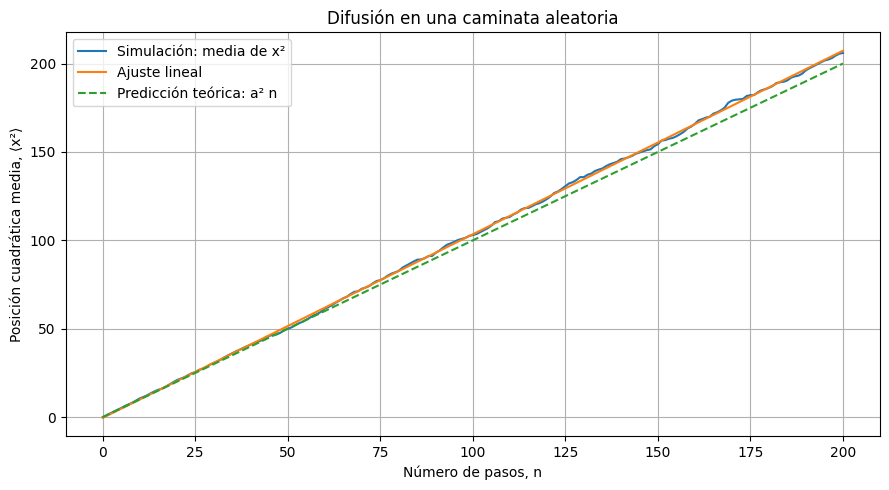

Gráfica guardada: caminata_difusion.png


In [ ]:

import csv
import matplotlib.pyplot as plt

# Calcula el valor ajustado de la posición cuadrática media para cada paso.
# La recta usa la pendiente y el intercepto obtenidos con ajuste_lineal.
ajuste = [pendiente * n + intercepto for n in pasos]

# Guarda los resultados en un archivo CSV con los encabezados solicitados.
with open("caminata_difusion.csv", "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.writer(archivo)

    # Escribe los nombres de las columnas.
    escritor.writerow(["n", "media_x", "media_x2", "ajuste"])

    # Escribe una fila por cada instante de la simulación.
    for n in range(N + 1):
        escritor.writerow([n, media_x[n], media_x2[n], ajuste[n]])

# Informa que el archivo se ha generado.
print("Archivo generado: caminata_difusion.csv")

# Crea la figura para comparar los datos simulados y el ajuste.
plt.figure(figsize=(9, 5))

# Representa la posición cuadrática media obtenida en la simulación.
plt.plot(pasos, media_x2, label="Simulación: media de x²")

# Representa la recta de ajuste calculada con ajuste_lineal.
plt.plot(pasos, ajuste, label="Ajuste lineal")

# Representa la predicción teórica para la caminata aleatoria.
plt.plot(
    pasos,
    [a**2 * n for n in pasos],
    "--",
    label="Predicción teórica: a² n"
)

# Añade título, etiquetas, unidades y cuadrícula.
plt.title("Difusión en una caminata aleatoria")
plt.xlabel("Número de pasos, n")
plt.ylabel("Posición cuadrática media, ⟨x²⟩")
plt.grid(True)
plt.legend()
plt.tight_layout()

# Guarda la gráfica y también la muestra en pantalla.
plt.savefig("caminata_difusion.png", dpi=150)
plt.show()

print("Gráfica guardada: caminata_difusion.png")


 Implementa el método de mínimos cuadrados directo sobre $\langle x_n^2 \rangle$ vs $n$ para calcular la pendiente $m$ sin depender de funciones externas (np.polyfit). Sirve para estimar el coeficiente de difusión ($D = m / 2\Delta t$).

## Parte C — Ejecutar, guardar y graficar

Complete los dos espacios de la celda siguiente y ejecútela después de terminar las funciones. El archivo CSV debe contener las columnas `n,media_x,media_x2,ajuste`, una fila por cada paso **incluido $n=0$**. En la figura muestre una caminata individual y, en otro panel, los valores promediados, la recta ajustada y la predicción teórica.

Reporte pendiente, intercepto y coeficiente de difusión $D$ con unidades. Aquí $a=1$ unidad de longitud y $\Delta t=1$ unidad de tiempo, de modo que el resultado de referencia es $D=0.5$ longitud$^2$/tiempo. Su valor simulado no tiene que coincidir exactamente. El valor de $D$ del informe debe proceder de `ajuste_lineal`.

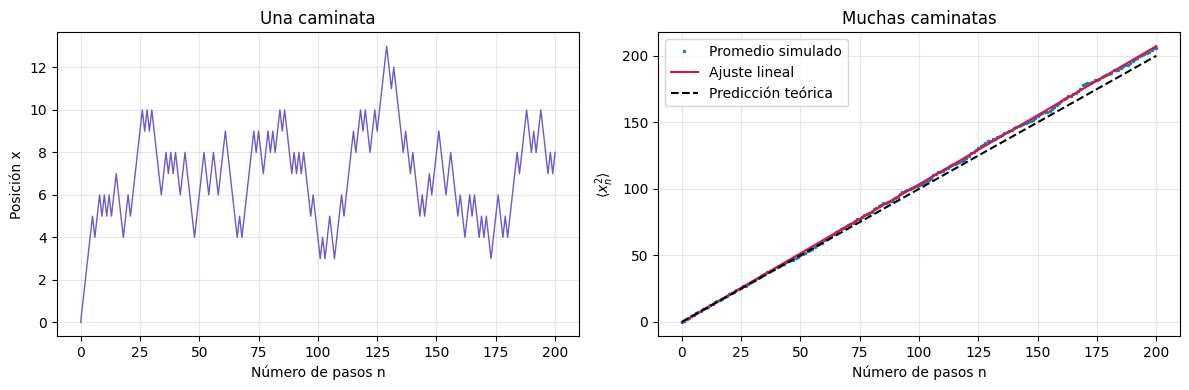

Pendiente=1.03839; intercepto=-0.40870
D estimado=0.51919; D teórico=0.50000 (longitud²/tiempo)


In [ ]:

# --- Parámetros del experimento ---
K, N = 2000, 200            # caminantes y pasos por caminante
a, delta_t = 1.0, 1.0       # longitud de paso e intervalo de tiempo
semilla = 2026              # semilla del resultado entregado

# --- Simulación y ajuste lineal de <x_n^2> frente a n ---
media_x, media_x2 = simular_caminatas(K, N, a, semilla)
pasos = list(range(N + 1))
pendiente, intercepto = ajuste_lineal(pasos, media_x2)

# --- Coeficiente de difusión: estimado (del ajuste) y teórico ---
D_estimado = pendiente / (2 * delta_t)  # Estima D usando la pendiente del ajuste.
D_teorico = a**2 / (2 * delta_t)        # Calcula D según el modelo teórico.
ajuste = [pendiente*n + intercepto for n in pasos]   # recta ajustada, para graficar

# --- Una trayectoria individual, para comparar con el promedio ---
# La semilla distinta permite mostrar una trayectoria reproducible e independiente.
trayectoria = caminar(N, a, random.Random(2027))

# --- Guardar los resultados en un archivo CSV ---
with open("caminata_difusion.csv", "w", encoding="utf-8") as archivo:
    archivo.write("n,media_x,media_x2,ajuste\n")
    for n in pasos:
        archivo.write(f"{n},{media_x[n]},{media_x2[n]},{ajuste[n]}\n")

# --- Figura: trayectoria individual (izquierda) y promedios (derecha) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(pasos, trayectoria, color="slateblue", linewidth=1)
ax1.set(xlabel="Número de pasos n", ylabel="Posición x", title="Una caminata")
ax2.plot(pasos, media_x2, ".", markersize=3, label="Promedio simulado")
ax2.plot(pasos, ajuste, color="crimson", label="Ajuste lineal")
ax2.plot(pasos, [n*a*a for n in pasos], "--", color="black", label="Predicción teórica")
ax2.set(xlabel="Número de pasos n", ylabel=r"$\langle x_n^2\rangle$", title="Muchas caminatas")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.savefig("caminata_difusion.png", dpi=180, bbox_inches="tight")
plt.show()

# --- Resumen numérico ---
print(f"Pendiente={pendiente:.5f}; intercepto={intercepto:.5f}")
print(f"D estimado={D_estimado:.5f}; D teórico={D_teorico:.5f} (longitud²/tiempo)")

### Exploración requerida

Repita la simulación con, por ejemplo, $K=100$ y $K=2000$, conservando $N$, $a$, $\Delta t$ y la semilla. Calcule el coeficiente de difusión $D$ en cada caso. Explique por qué la cercanía a $D_{\rm teórico}$ **no tiene que mejorar de manera monótona** en solo dos ejecuciones, aunque la precisión típica sí mejora al promediar más caminatas. Si cambia la semilla, documente el cambio.

**Extensión opcional (Computational Physics, Giordano, ejercicio 7.3):** modifique las probabilidades de derecha e izquierda. Compare $\langle x_n^2\rangle$ con $\operatorname{Var}(x_n)=\langle x_n^2\rangle-\langle x_n\rangle^2$. Discuta cuál separa la dispersión de la deriva promedio. No use $m/(2\Delta t)$ de $\langle x^2\rangle$ como coeficiente de difusión en presencia de deriva.

In [ ]:

# --- Exploración: efecto del número de caminantes sobre D ---

# Conservamos los parámetros del experimento original.
N = 200
a = 1.0
delta_t = 1.0
semilla = 2026
D_teorico = a**2 / (2 * delta_t)

# Comparamos dos cantidades de caminantes con la misma semilla.
for K in [100, 2000]:

    # Simulamos las caminatas y calculamos el promedio del cuadrado
    # de la posición para cada número de pasos.
    media_x, media_x2 = simular_caminatas(K, N, a, semilla)

    # Ajustamos una recta a <x_n^2> en función del número de pasos.
    pasos = list(range(N + 1))
    pendiente, intercepto = ajuste_lineal(pasos, media_x2)

    # Estimamos el coeficiente de difusión a partir de la pendiente.
    D_estimado = pendiente / (2 * delta_t)

    # Calculamos la diferencia relativa frente al valor teórico.
    error_relativo = abs(D_estimado - D_teorico) / D_teorico * 100

    # Mostramos los resultados para comparar ambos experimentos.
    print(f"K = {K}")
    print(f"  Pendiente = {pendiente:.5f}")
    print(f"  D estimado = {D_estimado:.5f}")
    print(f"  D teórico = {D_teorico:.5f}")
    print(f"  Diferencia relativa = {error_relativo:.2f}%")
    print()


K = 100
  Pendiente = 1.33523
  D estimado = 0.66761
  D teórico = 0.50000
  Diferencia relativa = 33.52%

K = 2000
  Pendiente = 1.03839
  D estimado = 0.51919
  D teórico = 0.50000
  Diferencia relativa = 3.84%



Se repitió la simulación para \(K=100\) y \(K=2000\), conservando \(N=200\), \(a=1\), \(\Delta t=1\) y la semilla \(2026\). Para \(K=100\), se obtuvo \(D=0.66761\), con una diferencia relativa del 33.52 % respecto al valor teórico de \(0.50000\). Para \(K=2000\), se obtuvo \(D=0.51919\), con una diferencia relativa del 3.84 %.

En esta prueba, el aumento del número de caminantes produjo una estimación más cercana al valor teórico. Esto ocurre porque promediar más caminatas suele reducir las fluctuaciones estadísticas. Sin embargo, la mejora no tiene que ser monótona en solo dos ejecuciones: debido al carácter aleatorio de la simulación, una muestra más pequeña puede producir accidentalmente un resultado más cercano al valor teórico. La comparación realizada ilustra una mejora, pero no demuestra que siempre ocurra de esa manera.

## Parte D — Efecto de un mal generador sobre el coeficiente de difusión

En las diapositivas se mostró que el generador congruencial $(a,c,M,r_1)=(57,1,256,10)$ produce pares consecutivos alineados en una rejilla. Ahora se medirá el efecto de ese defecto sobre **un resultado físico**: el coeficiente de difusión $D$.

La clase `GeneradorLCG` de la celda siguiente ya está completa. Tiene un método `random()` que devuelve $r_i/M$, igual que `random.Random`; por eso puede entregarse directamente a `simular_caminatas` mediante el argumento `generador`. Ejecútela sin modificarla.

### Actividades

1. Ejecute la simulación con $K=2000$, $N=200$, $a=1$, $\Delta t=1$ usando tres generadores: `random.Random(2026)`, el LCG deficiente `GeneradorLCG(57, 1, 256, 10)` y el LCG de parámetros de `drand48`, `GeneradorLCG(0x5DEECE66D, 11, 2**48, 10)`.
2. Ajuste una recta a $\langle x_n^2\rangle$ en cada caso con `ajuste_lineal` y calcule el coeficiente de difusión $D$. Guarde los resultados en `D_lcg_malo` y `D_drand48`.
3. Represente $\langle x_n^2\rangle$ frente a $n$ para los tres generadores en una misma figura.
4. Guarde en `trayectoria_lcg_larga` **una sola** caminata de 1024 pasos con el LCG deficiente e imprima la posición en $n = 0, 256, 512, 768, 1024$. Explique el resultado usando el período del generador.
5. Responda: ¿qué coeficiente de difusión habría reportado un investigador que usara este generador sin probarlo? ¿Por qué las pruebas de media y de pares consecutivos del Ejercicio 1 son necesarias antes de simular?


In [ ]:
class GeneradorLCG:
    """Generador lineal congruente r_{i+1} = (a r_i + c) mod M.

    El método random() devuelve r/M en [0, 1), con la misma interfaz que
    random.Random, de modo que puede reemplazarlo en simular_caminatas.
    """

    # --- Constructor: guarda los parámetros y el estado inicial (la semilla) ---
    def __init__(self, a, c, M, semilla):
        self.a, self.c, self.M = a, c, M
        self.r = semilla % M          # el estado siempre está en 0, ..., M-1

    # --- Un número nuevo: actualiza el estado y lo escala a [0, 1) ---
    def random(self):
        self.r = (self.a*self.r + self.c) % self.M   # recurrencia congruencial
        return self.r / self.M                       # división real


# --- Comprobación con la secuencia de las diapositivas (a=4, c=1, M=9, r1=3) ---
demo = GeneradorLCG(4, 1, 9, 3)
print([round(demo.random()*9) for _ in range(9)])  # debe dar 4, 8, 6, 7, 2, 0, 1, 5, 3


[4, 8, 6, 7, 2, 0, 1, 5, 3]


D con random.Random : 0.5192
D con LCG deficiente: 0.0862
D con LCG drand48   : 0.4855   (teórico 0.5)


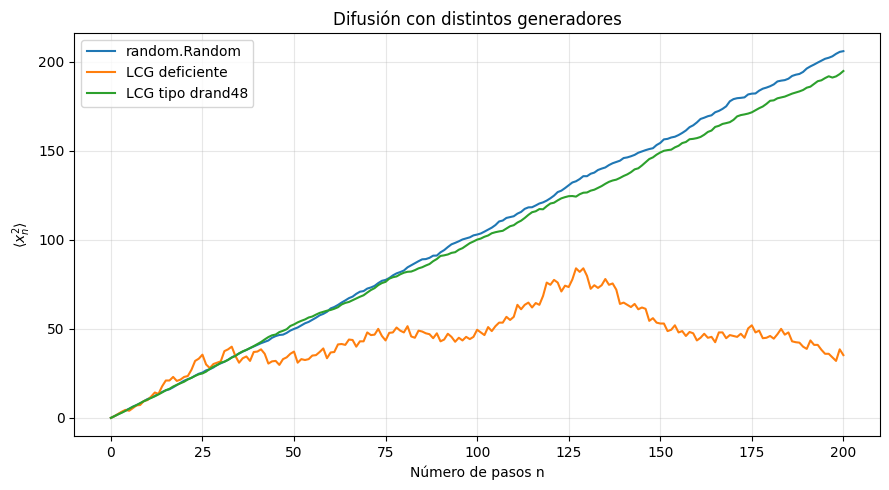

[0.0, 0.0, 0.0, 0.0, 0.0]


In [ ]:

# TODO: complete los espacios _____ y las dos gráficas indicadas al final.

# --- Parámetros comunes a los tres experimentos ---
K_gen, N_gen = 2000, 200
pasos_gen = list(range(N_gen + 1))

# --- Misma simulación con tres generadores distintos ---
_, x2_bueno = simular_caminatas(K_gen, N_gen, 1.0, 2026)  # random.Random
_, x2_malo = simular_caminatas(
    K_gen, N_gen, 1.0, None,
    generador=GeneradorLCG(57, 1, 256, 10)
)  # LCG (57, 1, 256, 10)

_, x2_drand48 = simular_caminatas(
    K_gen, N_gen, 1.0, None,
    generador=GeneradorLCG(0x5DEECE66D, 11, 2**48, 10)
)  # LCG de drand48, semilla 10

# --- Pendiente de <x_n^2> para cada generador ---
m_bueno, _ = ajuste_lineal(pasos_gen, x2_bueno)
m_malo, _ = ajuste_lineal(pasos_gen, x2_malo)
m_drand48, _ = ajuste_lineal(pasos_gen, x2_drand48)

# --- Coeficiente de difusión D = pendiente / (2 dt), con dt = 1 ---
D_bueno = m_bueno / 2
D_lcg_malo = m_malo / 2
D_drand48 = m_drand48 / 2

print(f"D con random.Random : {D_bueno:.4f}")
print(f"D con LCG deficiente: {D_lcg_malo:.4f}")
print(f"D con LCG drand48   : {D_drand48:.4f}   (teórico 0.5)")

# --- Gráfica comparativa ---
plt.figure(figsize=(9, 5))
plt.plot(pasos_gen, x2_bueno, label="random.Random")
plt.plot(pasos_gen, x2_malo, label="LCG deficiente")
plt.plot(pasos_gen, x2_drand48, label="LCG tipo drand48")
plt.xlabel("Número de pasos n")
plt.ylabel(r"$\langle x_n^2\rangle$")
plt.title("Difusión con distintos generadores")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# --- Una caminata larga con el LCG deficiente (actividad 4) ---
# Una caminata de 1024 pasos con GeneradorLCG(57, 1, 256, 10).
# Imprime la posición en n = 0, 256, 512, 768, 1024.
trayectoria_lcg_larga = caminar(
    1024, 1.0, GeneradorLCG(57, 1, 256, 10)
)
print([trayectoria_lcg_larga[n] for n in (0, 256, 512, 768, 1024)])

# Guarda la caminata completa para que PASS/FAIL pueda revisarla.



In [ ]:
# --- Diagnóstico de la caminata larga ---
print("Primeras 20 posiciones:", trayectoria_lcg_larga[:20])
print("Posición mínima:", min(trayectoria_lcg_larga))
print("Posición máxima:", max(trayectoria_lcg_larga))
print("Número de posiciones distintas:", len(set(trayectoria_lcg_larga)))

Primeras 20 posiciones: [0.0, 1.0, 2.0, 3.0, 4.0, 3.0, 2.0, 3.0, 2.0, 1.0, 2.0, 1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 5.0]
Posición mínima: -9.0
Posición máxima: 11.0
Número de posiciones distintas: 21


Se obtuvo \(D=0.5192\) con `random.Random`, \(D=0.0862\) con el LCG deficiente y \(D=0.4855\) con el LCG tipo drand48. Los dos primeros generadores de mejor comportamiento dieron valores más cercanos al teórico \(D=0.5\). Además, el LCG deficiente mostró un patrón periódico: la caminata regresó a cero en los pasos analizados, evidenciando cómo un generador inadecuado puede afectar la simulación.

## Parte E — Difusión en unidades reales

Hasta ahora $a=1$ y $\Delta t=1$ en unidades arbitrarias. Para dar sentido físico al resultado, considere una molécula de oxígeno disuelta en agua a temperatura ambiente, cuyo coeficiente de difusión $D$ es aproximadamente

$$D_{\rm O_2}\approx 2\times10^{-9}\ \text{m}^2/\text{s}.$$

El modelo de caminata reproduce ese valor si la longitud del paso y el intervalo cumplen $D=a^2/(2\Delta t)$. El tiempo característico para que el desplazamiento cuadrático medio alcance $L^2$ es, en una dimensión,

$$t(L)\approx\frac{L^2}{2D}.$$

### Actividades

1. Con $\Delta t = 1\ \mu\text{s}$, calcule la longitud de paso `a_fisico` (en metros) que reproduce $D_{\rm O_2}$.
2. Convierta la pendiente `pendiente` obtenida en la Parte C (en unidades de $a^2$ por paso) a un coeficiente de difusión en m²/s: $D_{\rm sim} = m\,a_{\rm fisico}^2/(2\Delta t)$. Compárelo con $D_{\rm O_2}$.
3. Calcule `t_celula`, `t_mm` y `t_cm`: el tiempo para difundir $L = 10\ \mu\text{m}$ (el tamaño de una célula), $1$ mm y $1$ cm. Exprese cada uno en la unidad más legible (s, min, h).
4. Calcule también el tiempo para $L = 1$ m en agua quieta y expréselo en años.
5. ¿Cuántos pasos $N$ necesitaría la simulación para representar la difusión a lo largo de 1 cm con el paso `a_fisico`? Comente por qué, a escalas grandes, se usa la ecuación de difusión en lugar de simular cada paso.
6. Discuta brevemente: la difusión basta para transportar oxígeno dentro de una célula, pero ¿basta para mezclar un contaminante en un lago? ¿Qué otro mecanismo de transporte domina a escalas grandes?


**Interpretación:** este tiempo corresponde a una distancia raíz cuadrática media $x_{\mathrm{rms}}=L$. No es el tiempo en que todas las partículas alcanzan $L$, ni garantiza mezcla completa. El paso `a_fisico` es una longitud efectiva de este modelo: no se identifica necesariamente con la distancia entre colisiones moleculares. El valor de $D_{\rm O_2}$ se usa como dato aproximado del ejercicio; depende de las condiciones del medio.


In [ ]:
# TODO: complete los espacios _____ (todo en unidades del SI).

# --- Datos físicos ---
D_O2 = 2e-9          # m^2/s, coeficiente de difusión del oxígeno en agua (aprox.)
dt_fisico = 1e-6     # s, intervalo de tiempo entre pasos

# --- Longitud de paso y coeficiente de difusión simulado ---
a_fisico = (2 * D_O2 * dt_fisico)**0.5
D_sim = (pendiente * a_fisico**2) / (2 * dt_fisico)


# --- Tiempo característico de difusión ---
def tiempo_difusion(L, D):
    """Tiempo t = L^2/(2D) para alcanzar una distancia RMS L en una dimensión."""
    return L**2 / (2 * D)

# --- Tiempos para distintas escalas de longitud ---
t_celula = tiempo_difusion(10e-6, D_O2)
t_mm = tiempo_difusion(1e-3, D_O2)
t_cm = tiempo_difusion(1e-2, D_O2)
t_m = tiempo_difusion(1.0, D_O2)

# --- Número de pasos que exigiría simular 1 cm con el paso a_fisico ---
N_cm = (1e-2 / a_fisico)**2

# --- Resultados en unidades legibles ---
print(f"a = {a_fisico*1e9:.1f} nm;  D_sim = {D_sim:.3e} m^2/s  (referencia {D_O2:.1e})")
print(f"10 µm: {t_celula:.3g} s")
print(f"1 mm : {t_mm:.3g} s = {t_mm/60:.3g} min")
print(f"1 cm : {t_cm:.3g} s = {t_cm/3600:.3g} h")
print(f"1 m  : {t_m/(3600*24*365.25):.3g} años")
print(f"Pasos para 1 cm: {N_cm:.2e}")


a = 63.2 nm;  D_sim = 2.077e-09 m^2/s  (referencia 2.0e-09)
10 µm: 0.025 s
1 mm : 250 s = 4.17 min
1 cm : 2.5e+04 s = 6.94 h
1 m  : 7.92 años
Pasos para 1 cm: 2.50e+10


In [ ]:
print("D_O2 =", D_O2)
print("dt_fisico =", dt_fisico)
print("a calculado =", (2 * D_O2 * dt_fisico)**0.5, "m")
print("a en nm =", (2 * D_O2 * dt_fisico)**0.5 * 1e9)

D_O2 = 2e-09
dt_fisico = 1e-06
a calculado = 6.324555320336758e-08 m
a en nm = 63.245553203367585


 Aplica el modelo al oxígeno en agua ($D_{\text{O}_2} \approx 2\times 10^{-9} \text{ m}^2/\text{s}$). Demuestra que la difusión es altamente eficiente a nivel celular ($10\ \mu\text{m} \to 0.025\text{ s}$), pero inviable a escalas métricas ($1\text{ m} \to 7.92\text{ años}$), justificando el uso de la advección/convección en la macroescala.

## Verificación final PASS/FAIL

Ejecute esta celda después de completar el taller. Las pruebas usan entradas controladas para verificar las funciones y revisan los archivos generados. La comparación estadística del valor de $D$ permite fluctuaciones razonables; no exige igualdad exacta. **Un PASS no reemplaza la revisión del código, las unidades, la figura y la interpretación física.**

In [ ]:
# --- Bibliotecas para leer el CSV y comparar números reales ---
import csv
import math
from pathlib import Path

# --- Registro de resultados: imprime PASS/FAIL y guarda cada veredicto ---
veredictos = []
def informar(nombre, condicion, detalle=""):
    estado = "PASS" if condicion else "FAIL"
    veredictos.append(condicion)
    print(f"{estado} | {nombre}" + (f" — {detalle}" if detalle else ""))

# --- Generador de prueba: devuelve valores fijados de antemano ---
class RngControlado:
    def __init__(self, valores):
        self.valores = iter(valores)
    def random(self):
        return next(self.valores)

# --- Prueba 1: regla del paso (umbral en 0.5) ---
try:
    pasos_prueba = [generar_paso(RngControlado([u]), 2.0) for u in (0.0, 0.49, 0.5, 0.99)]
    informar("Regla del paso y umbral 0.5", pasos_prueba == [2.0, 2.0, -2.0, -2.0])
except Exception as exc:
    informar("Regla del paso y umbral 0.5", False, str(exc))

# --- Prueba 2: trayectoria con números controlados ---
try:
    posiciones_prueba = list(caminar(4, 2.0, RngControlado([0.1, 0.7, 0.2, 0.8])))
    informar("Trayectoria y posición inicial", posiciones_prueba == [0.0, 2.0, 0.0, 2.0, 0.0])
except Exception as exc:
    informar("Trayectoria y posición inicial", False, str(exc))

# --- Prueba 3: ajuste lineal con datos exactos ---
try:
    m_prueba, b_prueba = ajuste_lineal([0, 1, 2, 3], [2, 5, 8, 11])
    informar("Ajuste lineal con datos conocidos", math.isclose(m_prueba, 3.0, abs_tol=1e-10) and math.isclose(b_prueba, 2.0, abs_tol=1e-10))
except Exception as exc:
    informar("Ajuste lineal con datos conocidos", False, str(exc))

# --- Pruebas 4-7: estructura, reproducibilidad, simetría y crecimiento difusivo ---
try:
    mx1, mx21 = simular_caminatas(2000, 100, 1.0, 12345)
    mx2, mx22 = simular_caminatas(2000, 100, 1.0, 12345)
    estructura = (len(mx1) == len(mx21) == 101 and
                  math.isclose(mx1[0], 0.0) and math.isclose(mx21[0], 0.0) and
                  all(math.isfinite(float(v)) for v in list(mx1) + list(mx21)))
    informar("Longitud, origen y valores finitos", estructura)
    informar("Reproducibilidad con la misma semilla", list(mx1) == list(mx2) and list(mx21) == list(mx22))
    if estructura:
        exactitud_media = all(abs(mx1[n]) <= 0.20*math.sqrt(n) + 0.1 for n in (25, 50, 100))
        informar("Media de posición compatible con simetría", exactitud_media)
        m_test, _ = ajuste_lineal(list(range(101)), mx21)
        informar("Crecimiento difusivo promedio", math.isfinite(m_test) and abs(m_test - 1.0) < 0.15, f"pendiente={m_test:.4f}")
    else:
        informar("Media de posición compatible con simetría", False)
        informar("Crecimiento difusivo promedio", False)
except Exception as exc:
    for nombre in ("Longitud, origen y valores finitos", "Reproducibilidad con la misma semilla", "Media de posición compatible con simetría", "Crecimiento difusivo promedio"):
        informar(nombre, False, str(exc))

# --- Prueba 8: parámetros inválidos deben producir ValueError ---
try:
    rechazos = []
    for llamada in (lambda: caminar(-1, 1.0, random.Random(1)),
                    lambda: simular_caminatas(0, 10, 1.0, 1),
                    lambda: ajuste_lineal([1, 1], [2, 3])):
        try:
            llamada()
            rechazos.append(False)
        except ValueError:
            rechazos.append(True)
    informar("Parámetros y ajuste degenerado rechazados", all(rechazos))
except Exception as exc:
    informar("Parámetros y ajuste degenerado rechazados", False, str(exc))

# --- Prueba 9: archivo CSV completo y consistente ---
try:
    datos = list(csv.DictReader(open("caminata_difusion.csv", encoding="utf-8")))
    columnas = set(datos[0]) if datos else set()
    valido = (len(datos) == N + 1 and columnas == {"n", "media_x", "media_x2", "ajuste"}
              and [int(fila["n"]) for fila in datos] == list(range(N+1)))
    if valido:
        valido = all(math.isclose(float(fila["media_x2"]), float(media_x2[i]), abs_tol=1e-10)
                     and math.isclose(float(fila["ajuste"]), pendiente*i + intercepto, abs_tol=1e-9)
                     for i, fila in enumerate(datos))
    informar("CSV completo y consistente con el ajuste", valido)
except Exception as exc:
    informar("CSV completo y consistente con el ajuste", False, str(exc))

# --- Prueba 10: conversión de la pendiente al coeficiente de difusión ---
try:
    correcto_D = (math.isclose(D_estimado, pendiente/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10)
                   and math.isclose(D_teorico, a*a/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10))
    informar("Conversión de la pendiente al coeficiente de difusión", correcto_D)
except Exception as exc:
    informar("Conversión de la pendiente al coeficiente de difusión", False, str(exc))

# --- Prueba 11: simular_caminatas acepta un generador externo (Parte D) ---
try:
    _, x2_ctrl = simular_caminatas(1, 2, 1.0, None, generador=RngControlado([0.1, 0.7]))
    informar("simular_caminatas acepta un generador externo", [float(t) for t in x2_ctrl] == [0.0, 1.0, 0.0])
except Exception as exc:
    informar("simular_caminatas acepta un generador externo", False, str(exc))

# --- Pruebas 12-13: coeficiente de difusión con el LCG deficiente y con drand48 ---
try:
    informar("LCG deficiente: resultado del experimento especificado", math.isfinite(D_lcg_malo) and math.isclose(D_lcg_malo, 0.08623725432244717, rel_tol=1e-6, abs_tol=1e-8), f"D_lcg_malo={D_lcg_malo:.4f}")
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", abs(D_drand48 - 0.5) < 0.075, f"D_drand48={D_drand48:.4f}")
except Exception as exc:
    informar("LCG deficiente: resultado del experimento especificado", False, str(exc))
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", False, str(exc))

# --- Pruebas 14-15: unidades reales (Parte E) ---
try:
# Verificamos que la longitud de paso calculada coincida con la fórmula
    # teórica.
    ok_a = math.isclose(a_fisico, math.sqrt(2*D_O2*dt_fisico), rel_tol=1e-9)
    ok_Dsim = math.isclose(D_sim, pendiente*a_fisico**2/(2*dt_fisico), rel_tol=1e-9)
    informar("Paso físico y coeficiente de difusión en m²/s", ok_a and ok_Dsim, f"a={a_fisico*1e9:.1f} nm, D_sim={D_sim:.2e} m²/s")
    ok_t = (math.isclose(t_celula, 0.025, rel_tol=1e-9) and math.isclose(t_cm, 2.5e4, rel_tol=1e-9)
            and math.isclose(t_mm, 250.0, rel_tol=1e-9) and math.isclose(t_m, 2.5e8, rel_tol=1e-9)
            and math.isclose(N_cm, (1e-2/a_fisico)**2, rel_tol=1e-6))
    informar("Tiempos de difusión y número de pasos", ok_t, f"t(10 µm)={t_celula:.3g} s, t(1 cm)={t_cm/3600:.2f} h")
except Exception as exc:
    informar("Paso físico y coeficiente de difusión en m²/s", False, str(exc))
    informar("Tiempos de difusión y número de pasos", False, str(exc))

# Prueba determinista de la caminata larga: no llama a las funciones del estudiante.
try:
    estado_ref = 10
    x_ref = 0.0
    recorrido_ref = [x_ref]
    for _ in range(1024):
        estado_ref = (57*estado_ref + 1) % 256
        x_ref += 1.0 if estado_ref/256 < 0.5 else -1.0
        recorrido_ref.append(x_ref)
    informar("Caminata larga con LCG: trayectoria y retornos periódicos",
             list(trayectoria_lcg_larga) == recorrido_ref)
except Exception as exc:
    informar("Caminata larga con LCG: trayectoria y retornos periódicos", False, str(exc))

# --- Prueba 16: la figura fue guardada ---
figura = Path("caminata_difusion.png")
informar("Figura generada", figura.is_file() and figura.stat().st_size > 1000)
# --- Resumen final ---
print(f"Resumen: {sum(veredictos)}/{len(veredictos)} PASS")

PASS | Regla del paso y umbral 0.5
PASS | Trayectoria y posición inicial
PASS | Ajuste lineal con datos conocidos
PASS | Longitud, origen y valores finitos
PASS | Reproducibilidad con la misma semilla
PASS | Media de posición compatible con simetría
PASS | Crecimiento difusivo promedio — pendiente=1.0147
PASS | Parámetros y ajuste degenerado rechazados
PASS | CSV completo y consistente con el ajuste
PASS | Conversión de la pendiente al coeficiente de difusión
PASS | simular_caminatas acepta un generador externo
PASS | LCG deficiente: resultado del experimento especificado — D_lcg_malo=0.0862
PASS | LCG drand48: coeficiente de difusión compatible con 0.5 — D_drand48=0.4855
PASS | Paso físico y coeficiente de difusión en m²/s — a=63.2 nm, D_sim=2.08e-09 m²/s
PASS | Tiempos de difusión y número de pasos — t(10 µm)=0.025 s, t(1 cm)=6.94 h
PASS | Caminata larga con LCG: trayectoria y retornos periódicos
PASS | Figura generada
Resumen: 17/17 PASS
